# Books, Interest & Mandates

A `Book` holds cash, positions and an append-only transaction log. One runner can
drive several books. Each accrues interest on its cash at the end of the day and can
reject trades through mandates.

In [1]:
from decimal import Decimal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from yabte.backtest import (
    Book,
    BookMandate,
    OrderSizeType,
    SimpleOrder,
    Strategy,
    StrategyRunner,
)
from yabte.tests._helpers import generate_nasdaq_dataset

assets, df_all = generate_nasdaq_dataset()
data = df_all.loc["2018"]
print(f"{len(data)} trading days in 2018")

251 trading days in 2018


## Several books

Pass a list of books to `StrategyRunner`. An order picks its book by name with
`book=`; without one it goes to the first book. Books never share cash or positions,
and each gets its own columns in the results.

Below, one strategy feeds two books: equal-weighted tech stocks in `Basket`, MSFT
alone in `Single`.

,ts,book,asset_name,quantity,price,total
0,2018-01-02,Basket,AAPL,585.62,42.69,-25000.1178
1,2018-01-02,Basket,AMZN,423.66,59.01,-25000.1766
2,2018-01-02,Basket,GOOG,473.48,52.80,-24999.7440
3,2018-01-02,Basket,MSFT,291.04,85.90,-25000.3360
0,2018-01-02,Single,MSFT,1164.14,85.90,-99999.6260


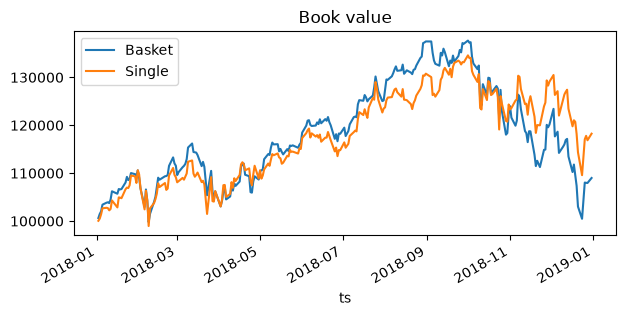

In [2]:
class TwoBooks(Strategy):
    def on_open(self):
        if len(self.data) == 1:
            names = ["AAPL", "AMZN", "GOOG", "MSFT"]
            for name in names:
                self.orders.append(
                    SimpleOrder(
                        book="Basket",
                        asset_name=name,
                        size=Decimal(100_000 / len(names)),
                        size_type=OrderSizeType.NOTIONAL,
                    )
                )
            self.orders.append(
                SimpleOrder(
                    book="Single",
                    asset_name="MSFT",
                    size=Decimal(100_000),
                    size_type=OrderSizeType.NOTIONAL,
                )
            )


srr = StrategyRunner(
    data=data,
    assets=assets,
    strategies=[TwoBooks()],
    books=[Book(name="Basket", cash="100000"), Book(name="Single", cash="100000")],
).run()

ax = srr.book_history.xs("total", axis=1, level=1).plot(
    title="Book value", figsize=(7, 3)
)
srr.transaction_history[["ts", "book", "asset_name", "quantity", "price", "total"]]

`book_history` is keyed by `(book, field)`. `transaction_history` carries a `book`
column.

## Interest on cash

`Book.rate` is a **daily** continuously compounded rate. At each end of day the book
receives `cash * (exp(rate) - 1)`, rounded to `interest_round_dp` and booked as a
`CashTransaction`. Negative cash pays it. Interest only accrues on days present in the
data, so an annual rate on trading-day data becomes `annual_rate / 252`.

`Cash` sits on 100,000 at 5% a year. `Leveraged` buys 150,000 of MSFT with 100,000
of cash and pays interest on the overdraft.

In [3]:
annual_rate = 0.05
daily_rate = Decimal(annual_rate / 252)


class BorrowToBuy(Strategy):
    def on_open(self):
        if len(self.data) == 1:
            self.orders.append(
                SimpleOrder(
                    book="Leveraged",
                    asset_name="MSFT",
                    size=Decimal(150_000),
                    size_type=OrderSizeType.NOTIONAL,
                )
            )


srr = StrategyRunner(
    data=data,
    assets=assets,
    strategies=[BorrowToBuy()],
    books=[
        Book(name="Cash", cash="100000", rate=daily_rate),
        Book(name="Leveraged", cash="100000", rate=daily_rate),
    ],
).run()

cash_book = srr.book_history.Cash
expected = 100_000 * np.exp(annual_rate * np.arange(1, len(data) + 1) / 252)
print(f"idle cash after {len(data)} days: {cash_book.cash.iloc[-1]:,.2f}")
print(f"100,000 x exp(5% x {len(data)}/252): {expected[-1]:,.2f}")

interest = srr.transaction_history.query("book == 'Leveraged'")
interest = interest[interest.desc.str.startswith("interest")]
print(f"interest paid on the overdraft: {interest.total.sum():,.2f}")
interest[["ts", "total", "desc"]].head(3)

idle cash after 251 days: 105,106.26
100,000 x exp(5% x 251/252): 105,106.25
interest paid on the overdraft: -2,553.14


,ts,total,desc
1,2018-01-02,-9.922,interest payment on cash -50000.30
2,2018-01-03,-9.924,interest payment on cash -50010.22
3,2018-01-04,-9.926,interest payment on cash -50020.14


Idle cash matches continuous compounding to within the daily rounding.

## Mandates

`BookMandate.check(current_pos, quantity)` runs before a trade is booked; return
`False` to reject it. Mandates are keyed by asset on the book:
`Book(mandates={asset_name: mandate})`. A rejected order isn't booked and ends with
status `MANDATE_FAILED`.

Mandates are experimental. Only the Python engine supports them, and the C++ engine
raises `ValueError` if any book has one.

In [4]:
class LongOnly(BookMandate):
    """No short positions."""

    def check(self, current_pos, quantity):
        return current_pos + quantity >= 0


class MaxPosition(BookMandate):
    """Position size limit, either side."""

    def __init__(self, limit):
        self.limit = limit

    def check(self, current_pos, quantity):
        return abs(current_pos + quantity) <= self.limit


class Trader(Strategy):
    """Buys and sells MSFT and AAPL on fixed days, regardless of the rules."""

    plan = {
        1: [("MSFT", 100), ("AAPL", 100)],
        5: [("MSFT", -150), ("AAPL", 250)],  # would go short / exceed the limit
        10: [("MSFT", -100), ("AAPL", 200)],  # within the rules
    }

    def on_open(self):
        for name, size in self.plan.get(len(self.data), []):
            self.orders.append(
                SimpleOrder(asset_name=name, size=size, label=f"{name} {size:+}")
            )


srr = StrategyRunner(
    data=data.iloc[:15],
    assets=assets,
    strategies=[Trader()],
    books=[
        Book(
            name="Main",
            cash="1000000",
            mandates={"MSFT": LongOnly(), "AAPL": MaxPosition(300)},
        )
    ],
).run()

display(
    pd.DataFrame(
        [(o.label, o.status.name) for o in srr.orders_processed],
        columns=["order", "status"],
    )
)
print("final positions:", dict(srr.books[0].positions))

,order,status
0,MSFT +100,COMPLETE
1,AAPL +100,COMPLETE
2,MSFT -150,MANDATE_FAILED
3,AAPL +250,MANDATE_FAILED
4,MSFT -100,COMPLETE
5,AAPL +200,COMPLETE


final positions: {'MSFT': Decimal('0.00'), 'AAPL': Decimal('300.00')}


The check sees an order's net quantity per asset. A `PositionalOrder` that flips from
long to short is judged on the net change, not on each leg.

`StrategyRunner(mandates=...)` only applies to the default `Main` book, created when no
`books` are passed. With explicit books it's ignored. Set mandates on each `Book`
instead.